# Input differential expression

Test gene-level expression differences between ASD and unaffected samples.


In [1]:
import os
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

REFERENCE = 'Unaffected'
TEST = 'ASD'
ALPHA = 0.05
MIN_COUNT = 10
N_CPUS = min(4, os.cpu_count() or 1)

sns.set_theme(style = 'ticks', context = 'notebook')


In [2]:
# Locate the project and load the analysis metadata.


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / 'data').is_dir():
            return path
    raise FileNotFoundError('Could not find the project data directory.')


ROOT = find_root(Path.cwd().resolve())
DATA_DIR = ROOT / 'data'
RESULTS_DIR = ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok = True)

metadata = pd.read_csv(DATA_DIR / 'metadata.tsv', sep = '\t', dtype = 'string')
metadata = metadata.set_index('sampleId')
metadata['condition'] = pd.Categorical(
    metadata['condition'],
    categories = [REFERENCE, TEST],
)
sample_ids = metadata.index.tolist()
min_samples = int(metadata['condition'].value_counts().min())


In [3]:
# Prepare length-scaled Salmon counts for the negative-binomial model.

path = DATA_DIR / 'Input' / 'salmon.merged.gene_counts_length_scaled.tsv'
table = pd.read_csv(path, sep = '\t')
columns = [f'input{sample_id}' for sample_id in sample_ids]
missing = {'gene_id', 'gene_name', *columns}.difference(table.columns)

if missing:
    raise ValueError(f'{path.name} is missing columns: {sorted(missing)}')
if table['gene_id'].isna().any() or not table['gene_id'].is_unique:
    raise ValueError('Gene identifiers must be complete and unique.')

gene_names = table.set_index('gene_id')['gene_name'].rename('geneName')
counts = table.set_index('gene_id').loc[:, columns]
counts.columns = sample_ids
counts = np.rint(counts.T).astype('int64')
counts.index.name = 'sampleId'
counts.columns.name = 'geneId'

keep = counts.ge(MIN_COUNT).sum(axis = 0).ge(min_samples)
model_counts = counts.loc[:, keep]

filter_summary = pd.DataFrame({
    'totalGenes': [counts.shape[1]],
    'retainedGenes': [model_counts.shape[1]],
    'minimumCount': [MIN_COUNT],
    'minimumSamples': [min_samples],
})
display(filter_summary)


,totalGenes,retainedGenes,minimumCount,minimumSamples
0,78941,21556,10,3


In [4]:
# Fit the DESeq2 model with unaffected samples as the reference.

dds = DeseqDataSet(
    counts = model_counts,
    metadata = metadata,
    design = '~condition',
    fit_type = 'parametric',
    size_factors_fit_type = 'ratio',
    refit_cooks = False,
    n_cpus = N_CPUS,
    quiet = True,
)
dds.deseq2()

coefficient = 'condition[T.ASD]'
if coefficient not in dds.varm['LFC'].columns:
    raise ValueError(f'Expected coefficient not found: {dds.varm["LFC"].columns}')


In [5]:
# Test ASD against unaffected while retaining maximum-likelihood effect estimates.

statistics = DeseqStats(
    dds,
    contrast = ['condition', TEST, REFERENCE],
    alpha = ALPHA,
    cooks_filter = True,
    independent_filter = True,
    n_cpus = N_CPUS,
    quiet = True,
)
with redirect_stdout(StringIO()):
    statistics.summary()

results = statistics.results_df.rename(columns = {
    'lfcSE': 'log2FoldChangeSE',
    'stat': 'statistic',
    'pvalue': 'pValue',
    'padj': 'adjustedPValue',
}).copy()
results.insert(0, 'geneName', gene_names.reindex(results.index))
results.index.name = 'geneId'
results['significant'] = results['adjustedPValue'].lt(ALPHA)
results = results.sort_values(
    ['adjustedPValue', 'pValue'],
    na_position = 'last',
)


In [6]:
# Summarize convergence, outlier handling, and discoveries.

model_summary = pd.DataFrame({
    'retainedGenes': [len(results)],
    'convergedGenes': [int(dds.var['_LFC_converged'].fillna(False).sum())],
    'undefinedPValueGenes': [int(results['pValue'].isna().sum())],
    'independentlyFilteredGenes': [int(
        (results['pValue'].notna() & results['adjustedPValue'].isna()).sum()
    )],
    'significantGenes': [int(results['significant'].sum())],
})
size_factors = dds.obs[['size_factors']].rename(
    columns = {'size_factors': 'sizeFactor'}
)

display(model_summary)
display(size_factors)
display(results.head(20))


,retainedGenes,convergedGenes,undefinedPValueGenes,independentlyFilteredGenes,significantGenes
0,21556,21556,71,836,305


,sizeFactor
sampleId,
07c06,1.106702
07c13,0.989767
07c16,0.960344
1851,1.000582
1861,0.984263
1916,0.996218


,geneName,baseMean,log2FoldChange,log2FoldChangeSE,statistic,pValue,adjustedPValue,significant
geneId,,,,,,,,
ENSG00000144820.10,ADGRG7,313.498689,6.905901,0.535309,12.900779,4.455682e-38,9.200538e-34,True
ENSG00000240342.3,RPS2P5,12041.899582,-4.331297,0.346499,-12.500181,7.448117e-36,7.689809e-32,True
ENSG00000289007.3,LINC03112,264.604550,6.624690,0.557793,11.876608,1.565934e-32,1.077832e-28,True
ENSG00000292360.2,LINC03112,306.758460,-7.506503,0.679209,-11.051831,2.147879e-28,1.108789e-24,True
ENSG00000133710.18,SPINK5,176.692741,4.771423,0.433715,11.001283,3.767323e-28,1.461994e-24,True
ENSG00000156804.9,FBXO32,1540.583148,4.119583,0.374833,10.990448,4.248131e-28,1.461994e-24,True
ENSG00000121068.16,TBX2,284.836884,-3.771677,0.346629,-10.881003,1.419914e-27,4.188543e-24,True
ENSG00000294153.1,ENSG00000294153,372.042581,6.449452,0.594015,10.857382,1.839471e-27,4.747905e-24,True
ENSG00000008196.14,TFAP2B,2234.941343,-3.264508,0.306356,-10.655919,1.636206e-26,3.754002e-23,True


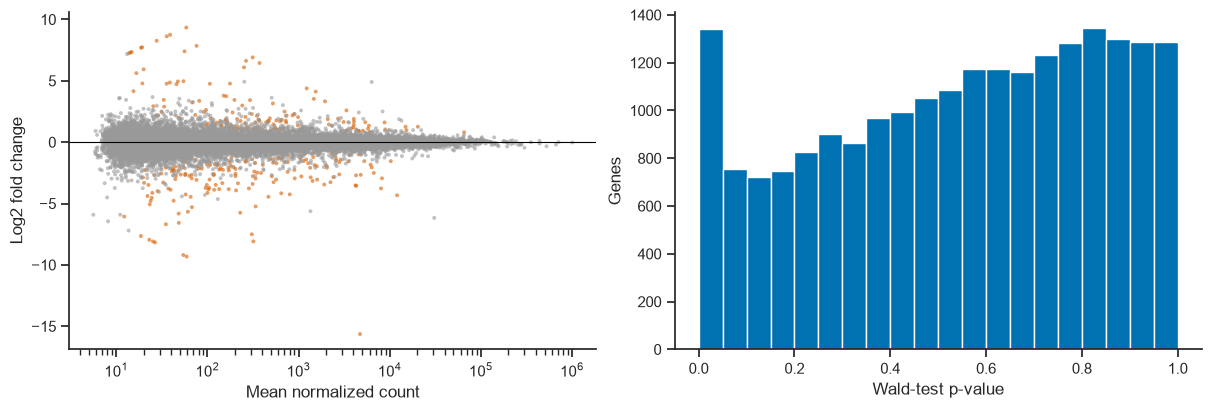

In [7]:
# Inspect effect sizes and the unadjusted p-value distribution.

figure, axes = plt.subplots(1, 2, figsize = (12, 4), constrained_layout = True)
colors = np.where(results['significant'], '#D55E00', '#999999')
axes[0].scatter(
    results['baseMean'],
    results['log2FoldChange'],
    c = colors,
    s = 8,
    alpha = 0.6,
    linewidths = 0,
)
axes[0].axhline(0, color = 'black', linewidth = 0.8)
axes[0].set(
    xscale = 'log',
    xlabel = 'Mean normalized count',
    ylabel = 'Log2 fold change',
)

axes[1].hist(
    results['pValue'].dropna(),
    bins = np.linspace(0, 1, 21),
    color = '#0072B2',
    edgecolor = 'white',
)
axes[1].set(xlabel = 'Wald-test p-value', ylabel = 'Genes')
sns.despine()
plt.show()


In [8]:
# Save the complete result table for downstream enrichment analyses.

results.reset_index().to_csv(
    RESULTS_DIR / 'inputDifferentialExpression.tsv',
    sep = '\t',
    index = False,
)
